In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv


In [2]:

import numpy as np
import pandas as pd

# Load the Concrete Compressive Strength dataset
df = pd.read_csv('/kaggle/input/datasets/elikplim/concrete-compressive-strength-data-set/concrete_data.csv')

# Display dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (1030, 9)

Column Names:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength']

First 5 Rows:


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Step 1: Clean the dataset
df_clean = df.dropna().drop_duplicates().copy()

# Step 2: Separate features and target
X = df_clean.drop(columns=['concrete_compressive_strength'])
y = df_clean['concrete_compressive_strength']

# Step 3: Split data (80% training, 20% testing)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Polynomial Features (degree = 2)
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_raw)
X_test_poly = poly.transform(X_test_raw)

# Step 5: Feature Scaling
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_poly)
X_test_scaled = scaler_X.transform(X_test_poly)

# Step 6: Target Scaling
scaler_y = StandardScaler()

y_train = scaler_y.fit_transform(
    y_train_raw.to_numpy().reshape(-1, 1)
).ravel()

y_test = scaler_y.transform(
    y_test_raw.to_numpy().reshape(-1, 1)
).ravel()

# Display results
print("Original Rows:", len(df))
print("Clean Rows:", len(df_clean))
print("Training Samples:", X_train_scaled.shape[0])
print("Testing Samples:", X_test_scaled.shape[0])
print("Polynomial Features:", X_train_scaled.shape[1])
print("Training Target Mean:", round(y_train.mean(), 4))


Original Rows: 1030
Clean Rows: 1005
Training Samples: 804
Testing Samples: 201
Polynomial Features: 44
Training Target Mean: 0.0


In [4]:

# Mini-Batch Gradient Descent from Scratch

# Add bias column (x0 = 1)
X_train_mb = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

# Initialize parameters
m_mb, n_mb = X_train_mb.shape
theta_mb = np.zeros(n_mb)

# Hyperparameters
learning_rate_mb = 0.001
epochs_mb = 2000
batch_size = 32

# Random generator for reproducibility
rng_mb = np.random.default_rng(42)

# Store cost values
cost_history_mb = []

# Calculate initial cost
initial_cost_mb = np.mean(y_train ** 2) / 2

# Mini-Batch Gradient Descent Training
for epoch in range(epochs_mb):

    # Shuffle training examples
    indices = rng_mb.permutation(m_mb)

    # Process data in mini-batches
    for start in range(0, m_mb, batch_size):

        batch_indices = indices[start:start + batch_size]

        X_batch = X_train_mb[batch_indices]
        y_batch = y_train[batch_indices]

        # Calculate predictions
        predictions = X_batch @ theta_mb

        # Calculate errors
        errors = predictions - y_batch

        # Calculate gradients
        gradients = (X_batch.T @ errors) / len(batch_indices)

        # Update parameters
        theta_mb -= learning_rate_mb * gradients

    # Calculate full training cost after each epoch
    full_predictions = X_train_mb @ theta_mb
    cost = np.mean((full_predictions - y_train) ** 2) / 2

    cost_history_mb.append(cost)

# Display results
print("Optimizer: Mini-Batch Gradient Descent")
print("Learning Rate:", learning_rate_mb)
print("Epochs:", epochs_mb)
print("Batch Size:", batch_size)
print("Number of Parameters:", n_mb)
print("Initial Cost:", round(initial_cost_mb, 6))
print("Final Cost:", round(cost_history_mb[-1], 6))


Optimizer: Mini-Batch Gradient Descent
Learning Rate: 0.001
Epochs: 2000
Batch Size: 32
Number of Parameters: 45
Initial Cost: 0.5
Final Cost: 0.109029


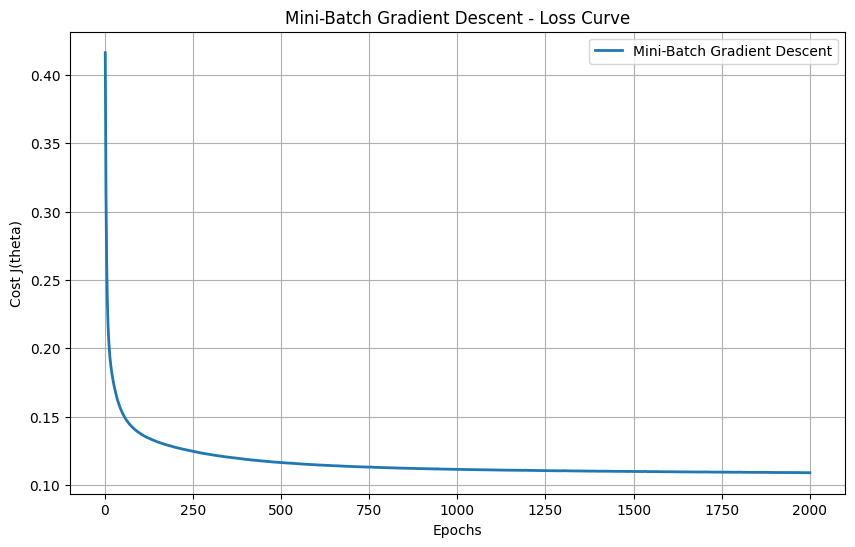

In [5]:

# Plot Mini-Batch Gradient Descent Loss Curve

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_mb + 1),
    cost_history_mb,
    label='Mini-Batch Gradient Descent',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('Mini-Batch Gradient Descent - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()


In [6]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Add bias column to test data
X_test_mb = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

# Make predictions
y_pred_scaled_mb = X_test_mb @ theta_mb

# Convert predictions to original scale
y_pred_mb = scaler_y.inverse_transform(
    y_pred_scaled_mb.reshape(-1, 1)
).ravel()

# Actual test values
y_actual = y_test_raw.to_numpy()

# Calculate evaluation metrics
mse_mb = mean_squared_error(y_actual, y_pred_mb)
rmse_mb = np.sqrt(mse_mb)
mae_mb = mean_absolute_error(y_actual, y_pred_mb)
r2_mb = r2_score(y_actual, y_pred_mb)

print("Mini-Batch GD - Test Results")
print("-----------------------------")
print("MSE:", round(mse_mb, 4))
print("RMSE:", round(rmse_mb, 4))
print("MAE:", round(mae_mb, 4))
print("R2 Score:", round(r2_mb, 4))


Mini-Batch GD - Test Results
-----------------------------
MSE: 68.877
RMSE: 8.2992
MAE: 6.1606
R2 Score: 0.7691


In [7]:

# Mini-Batch GD with Momentum from Scratch

# Initialize parameters
theta_mb_momentum = np.zeros(n_mb)
velocity_mb = np.zeros(n_mb)

# Hyperparameters
beta_mb = 0.9
learning_rate_mb_momentum = 0.0001

# Random generator
rng_mb_momentum = np.random.default_rng(42)

# Store cost values
cost_history_mb_momentum = []

# Training
for epoch in range(epochs_mb):

    # Shuffle training examples
    indices = rng_mb_momentum.permutation(m_mb)

    # Process mini-batches
    for start in range(0, m_mb, batch_size):

        batch_indices = indices[start:start + batch_size]

        X_batch = X_train_mb[batch_indices]
        y_batch = y_train[batch_indices]

        # Calculate predictions and errors
        predictions = X_batch @ theta_mb_momentum
        errors = predictions - y_batch

        # Calculate gradients
        gradients = (X_batch.T @ errors) / len(batch_indices)

        # Momentum update
        velocity_mb = beta_mb * velocity_mb + gradients

        # Update parameters
        theta_mb_momentum -= learning_rate_mb_momentum * velocity_mb

    # Calculate training cost
    full_predictions = X_train_mb @ theta_mb_momentum
    cost = np.mean((full_predictions - y_train) ** 2) / 2

    cost_history_mb_momentum.append(cost)

# Evaluate on test data
y_pred_momentum_scaled = X_test_mb @ theta_mb_momentum

y_pred_momentum = scaler_y.inverse_transform(
    y_pred_momentum_scaled.reshape(-1, 1)
).ravel()

rmse_mb_momentum = np.sqrt(
    mean_squared_error(y_actual, y_pred_momentum)
)

r2_mb_momentum = r2_score(y_actual, y_pred_momentum)

# Compare results
print("Mini-Batch GD vs Mini-Batch GD with Momentum")
print("-------------------------------------------")

print("Mini-Batch Final Cost:",
      round(cost_history_mb[-1], 6))

print("Momentum Final Cost:",
      round(cost_history_mb_momentum[-1], 6))

print("Mini-Batch Test RMSE:",
      round(rmse_mb, 4))

print("Momentum Test RMSE:",
      round(rmse_mb_momentum, 4))

print("Mini-Batch Test R2:",
      round(r2_mb, 4))

print("Momentum Test R2:",
      round(r2_mb_momentum, 4))


Mini-Batch GD vs Mini-Batch GD with Momentum
-------------------------------------------
Mini-Batch Final Cost: 0.109029
Momentum Final Cost: 0.10903
Mini-Batch Test RMSE: 8.2992
Momentum Test RMSE: 8.3054
Mini-Batch Test R2: 0.7691
Momentum Test R2: 0.7688


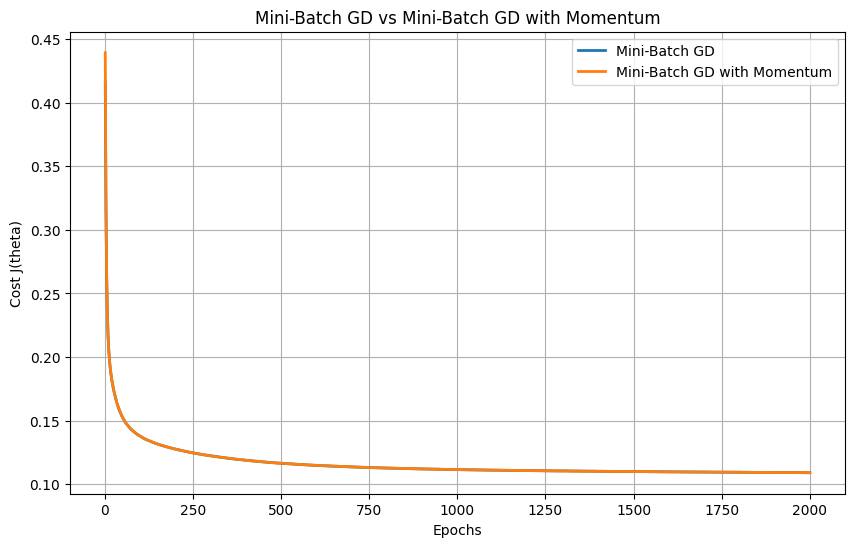

In [8]:

# Compare Mini-Batch GD and Mini-Batch GD with Momentum

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs_mb + 1),
    cost_history_mb,
    label='Mini-Batch GD',
    linewidth=2
)

plt.plot(
    range(1, epochs_mb + 1),
    cost_history_mb_momentum,
    label='Mini-Batch GD with Momentum',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost J(theta)')
plt.title('Mini-Batch GD vs Mini-Batch GD with Momentum')
plt.legend()
plt.grid(True)
plt.show()



## Results and Discussion

In this experiment, Polynomial Regression (degree = 2) was trained using Mini-Batch Gradient Descent and Mini-Batch Gradient Descent with Momentum.

### Experimental Results

| Metric | Mini-Batch GD | With Momentum |
|---|---|---|
| Final Training Cost | 0.109029 | 0.109030 |
| Test RMSE | 8.2992 | 8.3054 |
| Test R² | 0.7691 | 0.7688 |

### Discussion

Mini-Batch Gradient Descent successfully reduced the training cost over 2000 epochs using a batch size of 32.

Momentum was implemented with beta = 0.9 to incorporate information from previous gradients.

The loss curves were nearly identical, indicating similar convergence behavior under the selected settings.

Mini-Batch GD achieved a slightly lower test RMSE and a slightly higher R² score.

However, different learning rates were used, so the results cannot be attributed to Momentum alone.

### Conclusion

Both methods successfully optimized the Polynomial Regression model.

In this experiment, adding Momentum did not produce a meaningful improvement in predictive performance.

The results demonstrate that the effectiveness of Momentum depends on the learning rate and training configuration.
